# Praktikum Association Rule Mining (Apriori & FP-Growth)

**Kelompok 8**

| No | Nama Anggota | NIM |
|----|--------------|-----|
| 1 | Ahmad Naufal Azzuhdi | 24343029 |
| 2 | Dealexa Fatika Dzikra | 24343031 |

Program Studi Informatika, Fakultas Teknik, Universitas Negeri Padang

---

**Berkas yang dibutuhkan** (satu folder dengan notebook ini):
- `transactions_arm_praktikum.csv` → 60 transaksi toko kelontong (Lampiran A)
- `transactions_toko_baju.csv` → 50 transaksi toko baju (Lampiran B). Berkas ini **dibuat otomatis** oleh sel di bagian 20, jadi tidak perlu disiapkan manual.

**Instalasi:** `pip install pandas numpy matplotlib mlxtend`

**Cara menjalankan:** buka notebook di Jupyter / VS Code / Google Colab, lalu jalankan semua sel berurutan (*Run All*). Urutan penting karena sel-sel di bawah memakai variabel dari sel di atasnya.

**Isi singkat:** bagian 1–12 membahas pipeline dasar (frekuensi item → one-hot → Apriori → aturan → visualisasi → Apriori vs FP-Growth); bagian 13–19 adalah Tugas 1–3 (eksperimen min_support, min_confidence, metrik tambahan, dan perbandingan waktu); bagian 20–23 adalah Tugas 4 (dataset toko baju).


## 1. Import pustaka dan muat dataset

In [1]:
import time
import random
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules


def muat_transaksi(path):
    """Baca CSV (transaction_id, items) -> list of list item."""
    d = pd.read_csv(path)
    return [[i.strip() for i in s.split(',')] for s in d['items']]


transactions = muat_transaksi('transactions_arm_praktikum.csv')
print('Jumlah transaksi:', len(transactions))
for i, t in enumerate(transactions[:5], 1):
    print(f'T{i}: {t}')

Jumlah transaksi: 60
T1: ['Gula', 'Kopi', 'Susu']
T2: ['Gula', 'Kopi', 'Susu']
T3: ['Mentega', 'Roti', 'Susu', 'Telur']
T4: ['Mie Instan']
T5: ['Keju', 'Roti', 'Susu', 'Telur']


**Penjelasan (Sel 1 – Import & muat data):** Sel ini mengimpor pustaka yang dipakai (`pandas`, `numpy`, `matplotlib`, `mlxtend`) dan mendefinisikan fungsi `muat_transaksi()` yang membaca CSV lalu memecah kolom `items` (dipisah koma) menjadi *list* item per transaksi. Hasilnya: **60 transaksi** toko kelontong. Lima transaksi pertama ditampilkan untuk memastikan data terbaca benar, misalnya T1 berisi Gula, Kopi, Susu.

## 2. Frekuensi kemunculan item

In [2]:
cnt = Counter()
for t in transactions:
    cnt.update(t)
for item, freq in cnt.most_common():
    print(f'{item:12s}: {freq:2d} (support = {freq/len(transactions):.3f})')

Susu        : 19 (support = 0.317)
Roti        : 18 (support = 0.300)
Mie Instan  : 18 (support = 0.300)
Mentega     : 17 (support = 0.283)
Telur       : 15 (support = 0.250)
Sabun       : 15 (support = 0.250)
Gula        : 14 (support = 0.233)
Kopi        : 13 (support = 0.217)
Shampo      : 13 (support = 0.217)
Kecap       : 12 (support = 0.200)
Keju        :  6 (support = 0.100)
Teh         :  4 (support = 0.067)


**Penjelasan (Sel 2 – Frekuensi item):** `Counter` menghitung berapa kali tiap item muncul, lalu support-nya dihitung sebagai frekuensi ÷ 60. Susu paling sering dibeli (19 kali, support 0,317), diikuti Roti dan Mie Instan (masing-masing 0,300). Teh paling jarang (4 kali, support 0,067) dan Keju 6 kali (0,100). Ini memberi gambaran awal item mana yang berpeluang lolos ambang `min_support`.

## 3. Grafik frekuensi item

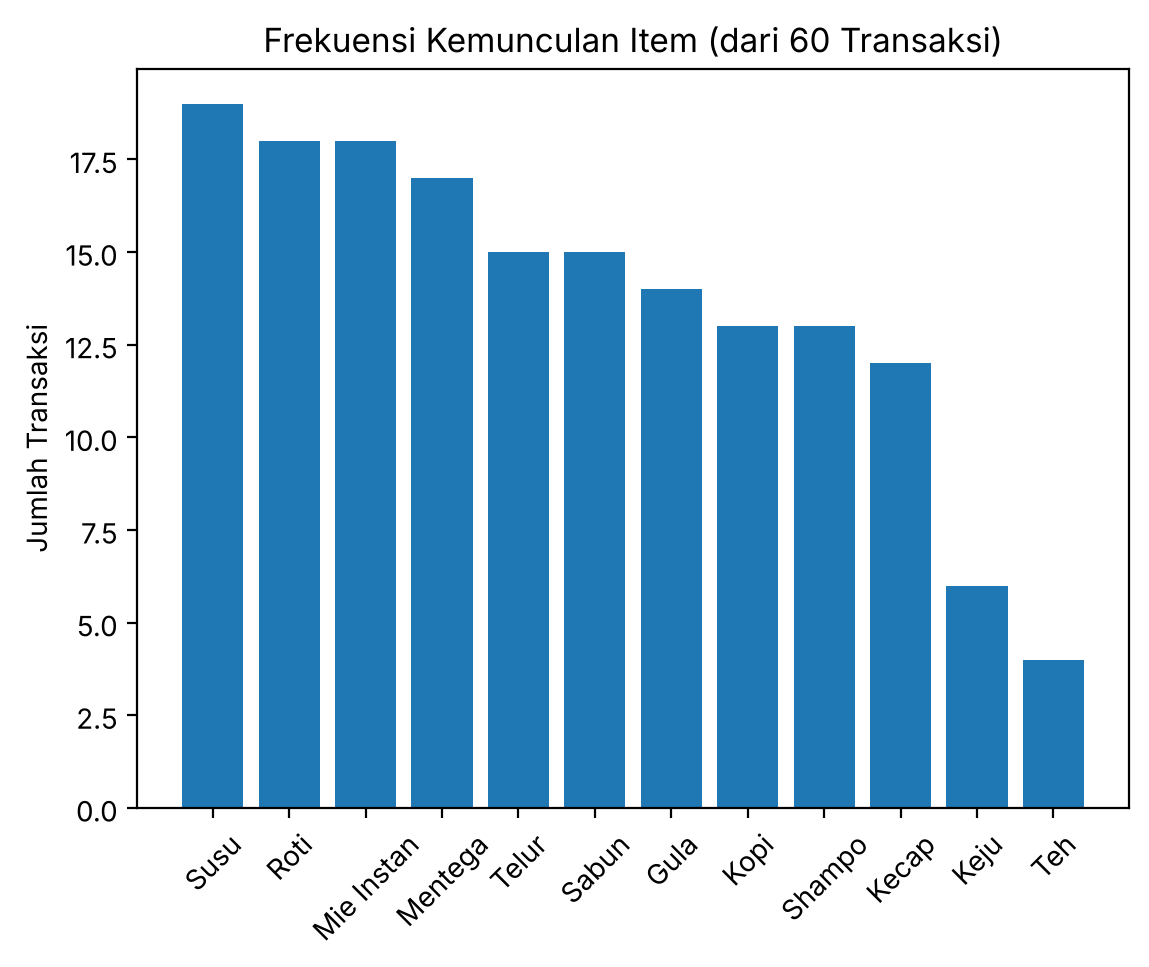

In [3]:
items, freqs = zip(*cnt.most_common())
plt.bar(items, freqs)
plt.xticks(rotation=45)
plt.ylabel('Jumlah Transaksi')
plt.title('Frekuensi Kemunculan Item (dari 60 Transaksi)')
plt.show()

**Penjelasan (Sel 3 – Grafik frekuensi):** Diagram batang dari hasil sel sebelumnya. Item diurutkan dari yang terbanyak, sehingga terlihat jelas Susu, Roti, dan Mie Instan di posisi atas, sedangkan Keju dan Teh jauh di bawah. Label sumbu-x diputar 45° agar tidak saling menimpa.

## 4. Encoding one-hot

In [4]:
te = TransactionEncoder()
te_ary = te.fit(transactions).transform(transactions)
df = pd.DataFrame(te_ary, columns=te.columns_)
print('Ukuran matriks one-hot:', df.shape)
print(df.iloc[:5, :6])

Ukuran matriks one-hot: (60, 12)
    Gula  Kecap   Keju   Kopi  Mentega  Mie Instan
0   True  False  False   True    False       False
1   True  False  False   True    False       False
2  False  False  False  False     True       False
3  False  False  False  False    False        True
4  False  False   True  False    False       False


**Penjelasan (Sel 4 – One-hot encoding):** `TransactionEncoder` mengubah daftar transaksi menjadi tabel boolean (baris = transaksi, kolom = item; `True` berarti item ada di transaksi itu). Ukurannya **60 × 12** (60 transaksi, 12 jenis item). Format ini wajib karena `apriori()` dan `fpgrowth()` dari mlxtend hanya menerima DataFrame one-hot.

## 5. Frequent itemset (Apriori)

In [5]:
MIN_SUP = 0.15
freq_apriori = apriori(df, min_support=MIN_SUP, use_colnames=True)
freq_apriori = freq_apriori.sort_values('support', ascending=False)
print('Jumlah frequent itemset:', len(freq_apriori))
print(freq_apriori.to_string(index=False))

Jumlah frequent itemset: 17
 support                         itemsets
0.316667                frozenset({Susu})
0.300000                frozenset({Roti})
0.300000          frozenset({Mie Instan})
0.283333             frozenset({Mentega})
0.250000               frozenset({Sabun})
0.250000               frozenset({Telur})
0.233333                frozenset({Gula})
0.216667              frozenset({Shampo})
0.216667                frozenset({Kopi})
0.216667          frozenset({Susu, Roti})
0.216667       frozenset({Mentega, Roti})
0.200000               frozenset({Kecap})
0.183333       frozenset({Susu, Mentega})
0.183333 frozenset({Susu, Mentega, Roti})
0.166667   frozenset({Mie Instan, Telur})
0.150000   frozenset({Mie Instan, Kecap})
0.150000       frozenset({Shampo, Sabun})


**Penjelasan (Sel 5 – Frequent itemset dengan Apriori):** Dengan `min_support = 0,15`, Apriori mencari semua itemset yang muncul minimal di 15% transaksi (≥ 9 dari 60). Ditemukan **17 frequent itemset**: 10 itemset tunggal dan 7 itemset berukuran 2–3, misalnya {Susu, Roti} (0,217), {Mentega, Roti} (0,217), dan {Susu, Mentega, Roti} (0,183). Keju dan Teh gugur karena support-nya di bawah 0,15.

## 6. Aturan asosiasi

In [6]:
MIN_CONF = 0.5
rules = association_rules(freq_apriori, metric='confidence', min_threshold=MIN_CONF)
rules = rules.sort_values('lift', ascending=False).reset_index(drop=True)
print('Jumlah aturan asosiasi:', len(rules))
cols = ['antecedents', 'consequents', 'support', 'confidence', 'lift']
print(rules[cols].round(3).to_string(index=False))

Jumlah aturan asosiasi: 18
               antecedents                consequents  support  confidence  lift
frozenset({Susu, Mentega})          frozenset({Roti})    0.183       1.000 3.333
         frozenset({Roti}) frozenset({Susu, Mentega})    0.183       0.611 3.333
      frozenset({Mentega})    frozenset({Susu, Roti})    0.183       0.647 2.986
   frozenset({Susu, Roti})       frozenset({Mentega})    0.183       0.846 2.986
        frozenset({Sabun})        frozenset({Shampo})    0.150       0.600 2.769
       frozenset({Shampo})         frozenset({Sabun})    0.150       0.692 2.769
         frozenset({Susu}) frozenset({Mentega, Roti})    0.183       0.579 2.672
frozenset({Mentega, Roti})          frozenset({Susu})    0.183       0.846 2.672
      frozenset({Mentega})          frozenset({Roti})    0.217       0.765 2.549
         frozenset({Roti})       frozenset({Mentega})    0.217       0.722 2.549
   frozenset({Mie Instan})         frozenset({Kecap})    0.150       0.500 2.500
 

**Penjelasan (Sel 6 – Aturan asosiasi):** Dari frequent itemset dibentuk aturan *antecedent → consequent* dengan `min_confidence = 0,5`, menghasilkan **18 aturan**, diurutkan menurut *lift*. Aturan terkuat adalah {Susu, Mentega} → {Roti} dengan confidence 1,000 dan lift 3,333, artinya setiap pembeli Susu + Mentega juga membeli Roti, dan peluangnya 3,3 kali lebih besar dibanding peluang Roti dibeli secara umum. Lift > 1 pada semua aturan menandakan hubungan yang positif.

## 7. Visualisasi: scatter Support vs Confidence

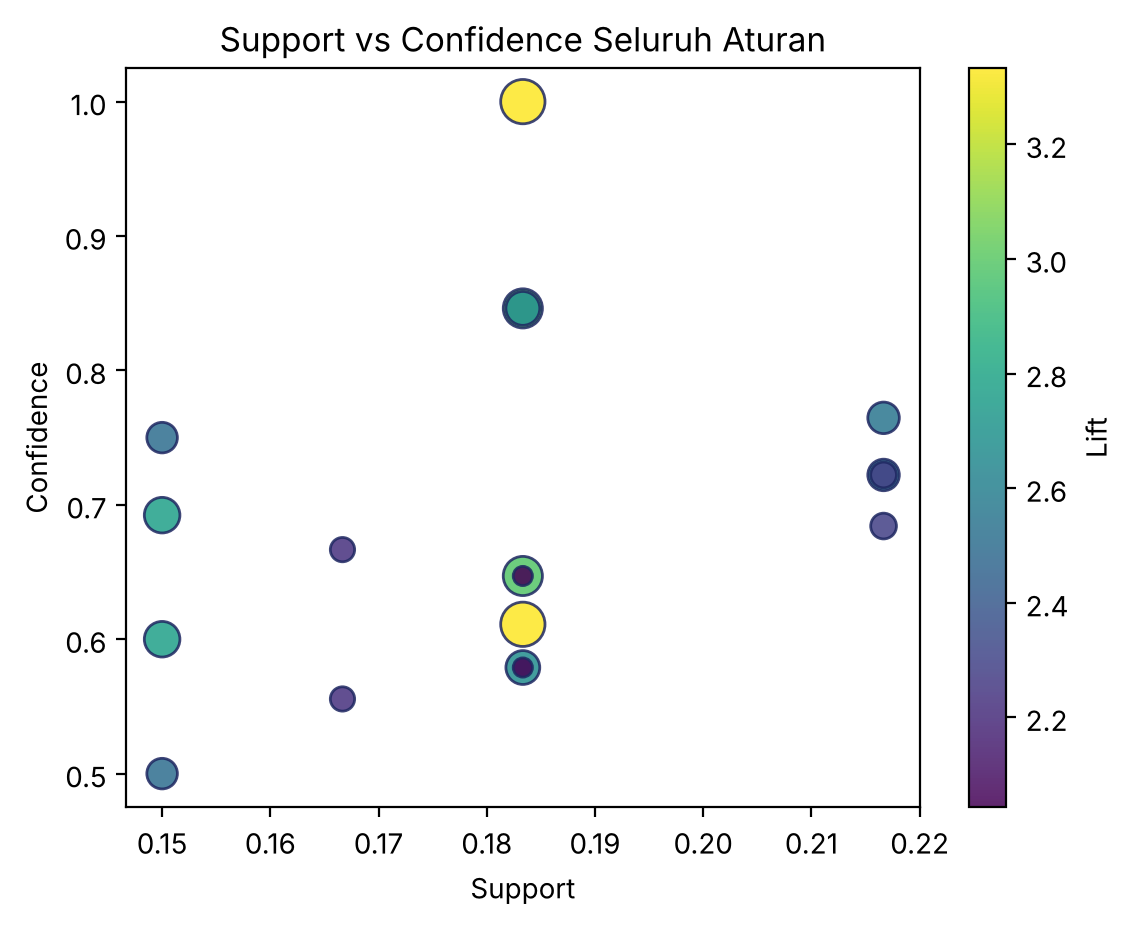

In [7]:
sizes = (rules['lift'] - rules['lift'].min() + 0.3) * 160
sc = plt.scatter(rules['support'], rules['confidence'], s=sizes,
                 c=rules['lift'], cmap='viridis', alpha=0.85, edgecolor='#1E2761')
plt.colorbar(sc, label='Lift')
plt.xlabel('Support'); plt.ylabel('Confidence')
plt.title('Support vs Confidence Seluruh Aturan')
plt.show()

**Penjelasan (Sel 7 – Scatter Support vs Confidence):** Setiap titik adalah satu aturan. Sumbu-x = support, sumbu-y = confidence, ukuran dan warna titik = lift. Titik yang berada di kanan atas dan berwarna terang (lift tinggi) adalah aturan yang paling layak diprioritaskan karena sering muncul sekaligus andal.

## 8. Visualisasi: 8 aturan dengan Lift tertinggi

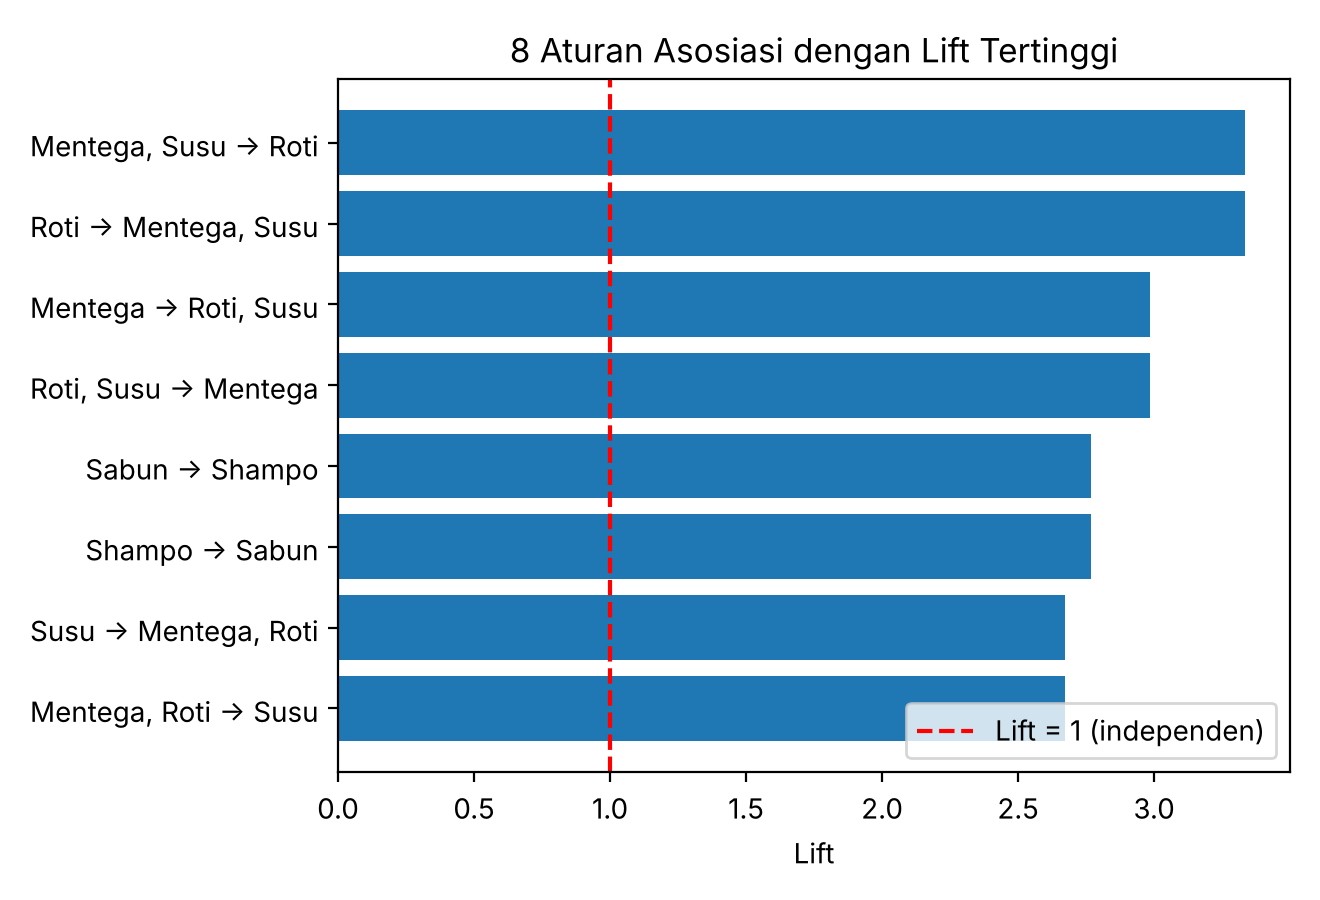

In [8]:
top8 = rules.head(8).copy()
labels = [', '.join(sorted(a)) + ' → ' + ', '.join(sorted(c))
          for a, c in zip(top8['antecedents'], top8['consequents'])]
plt.barh(labels[::-1], top8['lift'][::-1])
plt.axvline(1, color='red', linestyle='--', label='Lift = 1 (independen)')
plt.xlabel('Lift')
plt.title('8 Aturan Asosiasi dengan Lift Tertinggi')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

**Penjelasan (Sel 8 – 8 aturan lift tertinggi):** Diagram batang horizontal untuk 8 aturan dengan lift terbesar; garis merah putus-putus pada lift = 1 menandai batas independen (item tidak saling berkaitan). Semua batang jauh di kanan garis merah, sehingga kedelapan aturan benar-benar punya asosiasi. Aturan didominasi kombinasi Susu–Mentega–Roti dan pasangan Sabun–Shampo. *(Perbaikan: legenda dipindah ke kanan bawah agar tidak menutupi batang teratas.)*

## 9. Eksperimen: pengaruh min_support

In [9]:
sweep_sup = [0.10, 0.15, 0.20, 0.25, 0.30, 0.35, 0.40]
for s in sweep_sup:
    fi = apriori(df, min_support=s, use_colnames=True)
    r = association_rules(fi, metric='confidence', min_threshold=0.5) if len(fi) else pd.DataFrame()
    print(f'min_support={s:.2f}: {len(fi):2d} itemset, {len(r):2d} aturan')

min_support=0.10: 19 itemset, 20 aturan
min_support=0.15: 17 itemset, 18 aturan
min_support=0.20: 12 itemset,  4 aturan
min_support=0.25:  6 itemset,  0 aturan
min_support=0.30:  3 itemset,  0 aturan
min_support=0.35:  0 itemset,  0 aturan
min_support=0.40:  0 itemset,  0 aturan


**Penjelasan (Sel 9 – Eksperimen min_support):** Apriori dijalankan berulang dengan `min_support` 0,10 sampai 0,40. Makin tinggi ambang batas, makin sedikit itemset dan aturan: 19 itemset/20 aturan pada 0,10; 12/4 pada 0,20; pada 0,25 tersisa 6 itemset (semuanya item tunggal) sehingga **tidak ada aturan**; dan pada ≥ 0,35 tidak ada itemset sama sekali. Jadi `min_support` terlalu tinggi membuat pola penting hilang.

## 10. Grafik pengaruh min_support

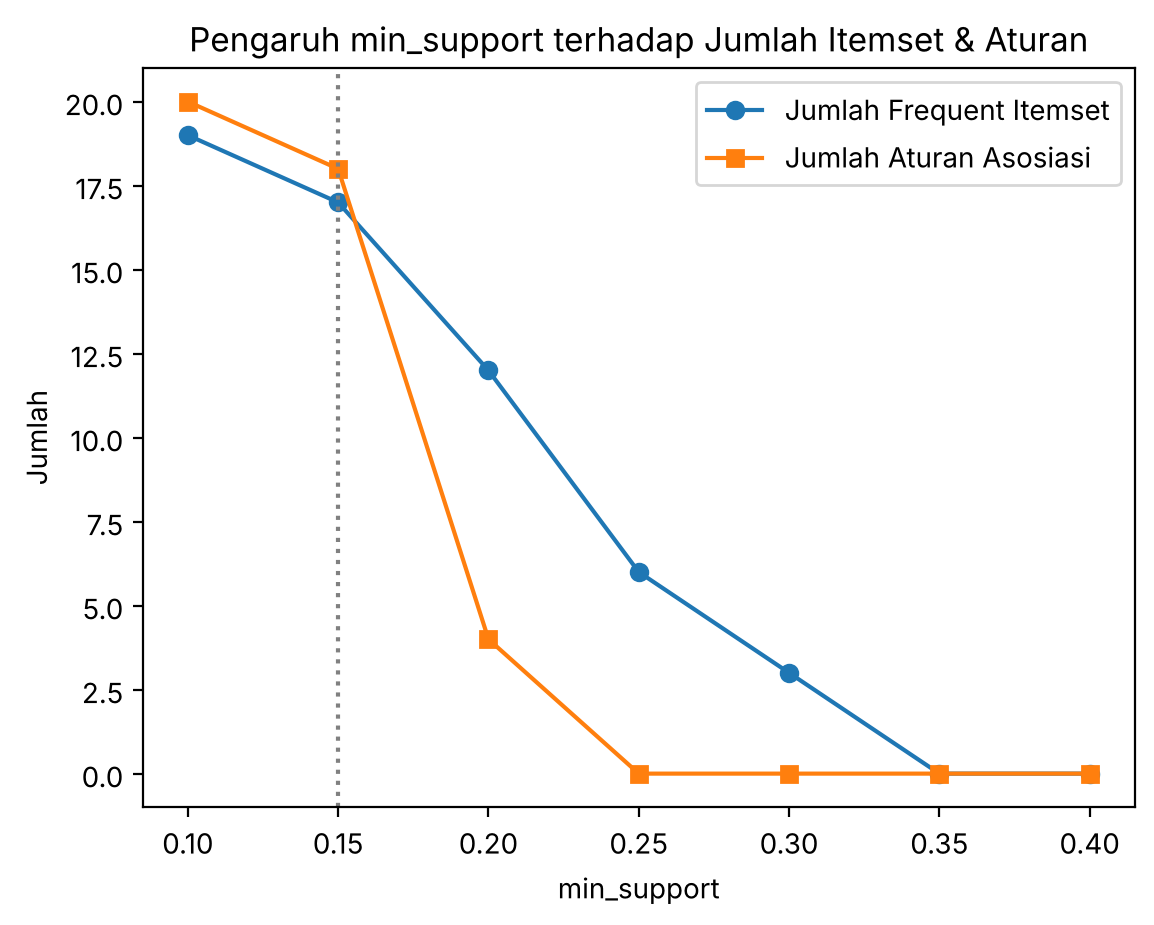

In [10]:
n_item, n_rule = [], []
for s in sweep_sup:
    fi = apriori(df, min_support=s, use_colnames=True)
    r = association_rules(fi, metric='confidence', min_threshold=0.5) if len(fi) else pd.DataFrame()
    n_item.append(len(fi)); n_rule.append(len(r))
plt.plot(sweep_sup, n_item, 'o-', label='Jumlah Frequent Itemset')
plt.plot(sweep_sup, n_rule, 's-', label='Jumlah Aturan Asosiasi')
plt.axvline(0.15, color='gray', linestyle=':')
plt.xlabel('min_support'); plt.ylabel('Jumlah')
plt.title('Pengaruh min_support terhadap Jumlah Itemset & Aturan')
plt.legend()
plt.show()

**Penjelasan (Sel 10 – Grafik pengaruh min_support):** Visualisasi dari sel sebelumnya berupa dua garis (jumlah itemset dan jumlah aturan) terhadap `min_support`. Keduanya menurun, dan jumlah aturan turun lebih tajam karena aturan butuh itemset berukuran ≥ 2. Garis putus-putus abu-abu di 0,15 adalah nilai yang dipilih di praktikum ini.

## 11. Apriori vs FP-Growth (satu kali eksekusi, min_support = 0.15)

In [11]:
t0 = time.perf_counter()
freq_apriori = apriori(df, min_support=0.15, use_colnames=True)
t_apriori = time.perf_counter() - t0

t0 = time.perf_counter()
freq_fpgrowth = fpgrowth(df, min_support=0.15, use_colnames=True)
t_fpgrowth = time.perf_counter() - t0

set_apriori = set(frozenset(s) for s in freq_apriori['itemsets'])
set_fpgrowth = set(frozenset(s) for s in freq_fpgrowth['itemsets'])
print(f'Apriori : {len(freq_apriori)} itemset, {t_apriori*1000:.2f} ms')
print(f'FP-Growth: {len(freq_fpgrowth)} itemset, {t_fpgrowth*1000:.2f} ms')
print('Itemset identik?', set_apriori == set_fpgrowth)

Apriori : 17 itemset, 3.32 ms
FP-Growth: 17 itemset, 2.01 ms
Itemset identik? True


**Penjelasan (Sel 11 – Apriori vs FP-Growth):** Kedua algoritma dijalankan pada data dan `min_support` yang sama (0,15), lalu waktunya diukur dengan `time.perf_counter()`. Hasilnya sama persis (17 itemset, `Itemset identik? True`), hanya waktunya berbeda: Apriori ≈ 3,32 ms dan FP-Growth ≈ 2,01 ms. Artinya kedua algoritma menghasilkan pola yang sama, FP-Growth lebih cepat karena tidak membuat kandidat itemset berulang. Perlu diingat ini satu kali ukur sehingga masih bisa berfluktuasi (dikoreksi di Sel 18).

## 12. Grafik waktu eksekusi

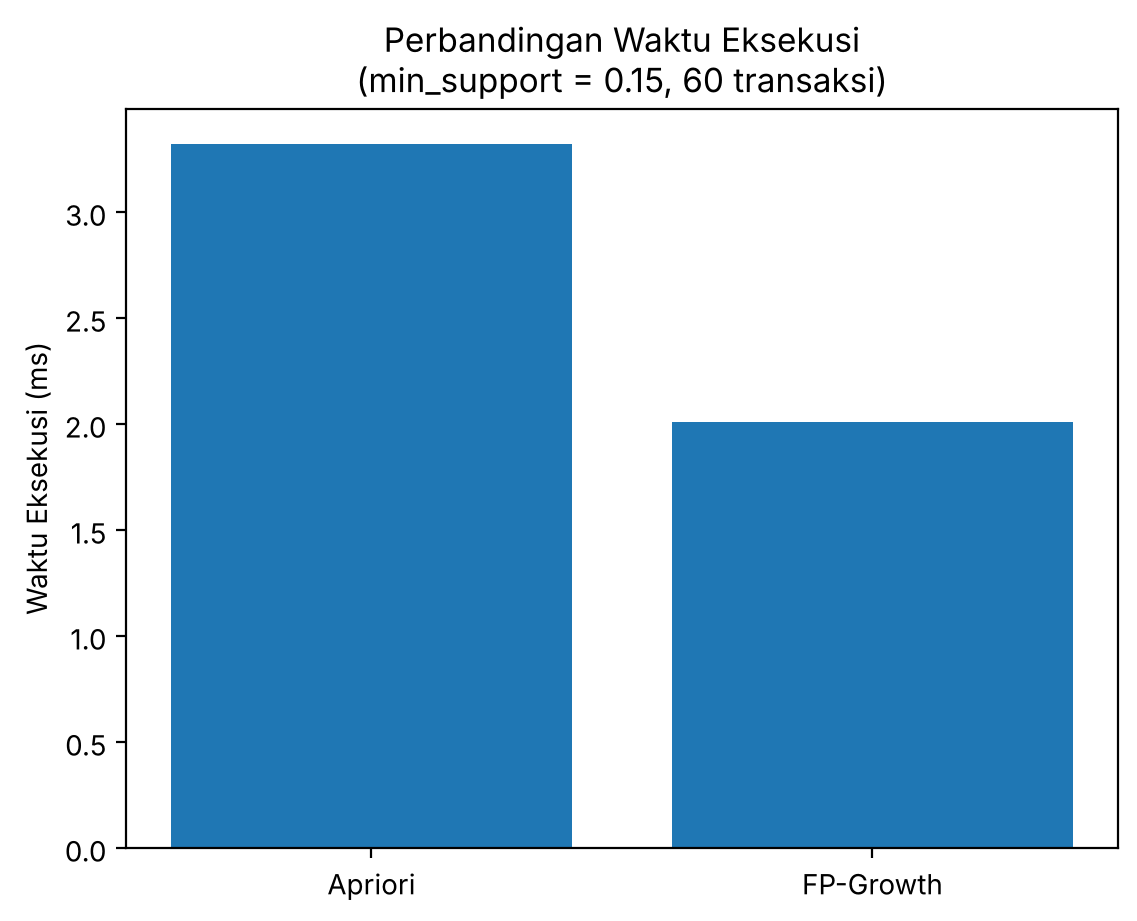

In [12]:
plt.bar(['Apriori', 'FP-Growth'], [t_apriori*1000, t_fpgrowth*1000])
plt.ylabel('Waktu Eksekusi (ms)')
plt.title('Perbandingan Waktu Eksekusi\n(min_support = 0.15, 60 transaksi)')
plt.show()

**Penjelasan (Sel 12 – Grafik waktu eksekusi):** Diagram batang yang membandingkan waktu eksekusi Apriori dan FP-Growth dari sel sebelumnya (dalam milidetik). Batang FP-Growth lebih pendek.

## 13. Tugas 1a: min_support 0.10 vs 0.15

In [13]:
fi_010 = apriori(df, min_support=0.10, use_colnames=True)
rules_010 = association_rules(fi_010, metric='confidence', min_threshold=0.5)
fi_015 = apriori(df, min_support=0.15, use_colnames=True)
rules_015 = association_rules(fi_015, metric='confidence', min_threshold=0.5)
print(f'min_support=0.10: {len(fi_010)} itemset, {len(rules_010)} aturan')
print(f'min_support=0.15: {len(fi_015)} itemset, {len(rules_015)} aturan')

fmt = lambda s: '{' + ', '.join(sorted(s)) + '}'
print('\nItemset tambahan pada min_support=0.10:')
for _, r in fi_010[~fi_010['itemsets'].isin(fi_015['itemsets'])].iterrows():
    print(f'  {fmt(r["itemsets"])}  support={r["support"]:.3f}')
key = lambda r: (r['antecedents'], r['consequents'])
rk_015 = {key(r) for _, r in rules_015.iterrows()}
print('\nAturan tambahan pada min_support=0.10:')
for _, r in rules_010.iterrows():
    if key(r) not in rk_015:
        print(f'  {fmt(r["antecedents"])} -> {fmt(r["consequents"])}  '
              f'conf={r["confidence"]:.3f} lift={r["lift"]:.3f}')

min_support=0.10: 19 itemset, 20 aturan
min_support=0.15: 17 itemset, 18 aturan

Itemset tambahan pada min_support=0.10:
  {Keju}  support=0.100
  {Gula, Kopi}  support=0.133

Aturan tambahan pada min_support=0.10:
  {Kopi} -> {Gula}  conf=0.615 lift=2.637
  {Gula} -> {Kopi}  conf=0.571 lift=2.637


**Penjelasan (Sel 13 – Tugas 1a: min_support 0,10 vs 0,15):** Sel ini membandingkan hasil kedua ambang batas dan mencetak selisihnya. Menurunkan `min_support` ke 0,10 menambah 2 itemset ({Keju} dengan support 0,100 dan {Gula, Kopi} dengan 0,133) dan 2 aturan: {Kopi} → {Gula} (confidence 0,615, lift 2,637) dan {Gula} → {Kopi} (confidence 0,571, lift 2,637). Pasangan Gula–Kopi sebelumnya tidak terlihat, padahal liftnya cukup tinggi.

## 14. Tugas 1b: min_confidence = 0.7

In [14]:
rules_07 = rules[rules['confidence'] >= 0.7]
gugur = rules[rules['confidence'] < 0.7]
print(f'Aturan awal (min_confidence=0.5): {len(rules)}')
print(f'Lolos min_confidence=0.7        : {len(rules_07)}')
print(f'Gugur                           : {len(gugur)}')
print('\nAturan yang gugur:')
for _, r in gugur.iterrows():
    print(f'  {fmt(r["antecedents"])} -> {fmt(r["consequents"])}  confidence={r["confidence"]:.3f}')
print('\nAturan yang lolos:')
for _, r in rules_07.iterrows():
    print(f'  {fmt(r["antecedents"])} -> {fmt(r["consequents"])}  confidence={r["confidence"]:.3f}')

Aturan awal (min_confidence=0.5): 18
Lolos min_confidence=0.7        : 7
Gugur                           : 11

Aturan yang gugur:
  {Roti} -> {Mentega, Susu}  confidence=0.611
  {Mentega} -> {Roti, Susu}  confidence=0.647
  {Sabun} -> {Shampo}  confidence=0.600
  {Shampo} -> {Sabun}  confidence=0.692
  {Susu} -> {Mentega, Roti}  confidence=0.579
  {Mie Instan} -> {Kecap}  confidence=0.500
  {Susu} -> {Roti}  confidence=0.684
  {Telur} -> {Mie Instan}  confidence=0.667
  {Mie Instan} -> {Telur}  confidence=0.556
  {Susu} -> {Mentega}  confidence=0.579
  {Mentega} -> {Susu}  confidence=0.647

Aturan yang lolos:
  {Mentega, Susu} -> {Roti}  confidence=1.000
  {Roti, Susu} -> {Mentega}  confidence=0.846
  {Mentega, Roti} -> {Susu}  confidence=0.846
  {Mentega} -> {Roti}  confidence=0.765
  {Roti} -> {Mentega}  confidence=0.722
  {Kecap} -> {Mie Instan}  confidence=0.750
  {Roti} -> {Susu}  confidence=0.722


**Penjelasan (Sel 14 – Tugas 1b: min_confidence = 0,7):** Aturan hasil Sel 6 disaring dengan ambang confidence 0,7. Dari 18 aturan, **7 lolos** dan **11 gugur**. Yang lolos antara lain {Mentega, Susu} → {Roti} (1,000), {Roti, Susu} → {Mentega} dan {Mentega, Roti} → {Susu} (0,846), {Kecap} → {Mie Instan} (0,750). Yang gugur misalnya {Sabun} → {Shampo} (0,600) dan {Mie Instan} → {Kecap} (0,500). Perhatikan bahwa aturan berarah: {Kecap} → {Mie Instan} lolos, tetapi arah sebaliknya gugur.

## 15. Tugas 1c: sweep min_confidence

min_confidence=0.5: 18 aturan
min_confidence=0.6: 14 aturan
min_confidence=0.7:  7 aturan
min_confidence=0.8:  3 aturan
min_confidence=0.9:  1 aturan
min_confidence=1.0:  1 aturan


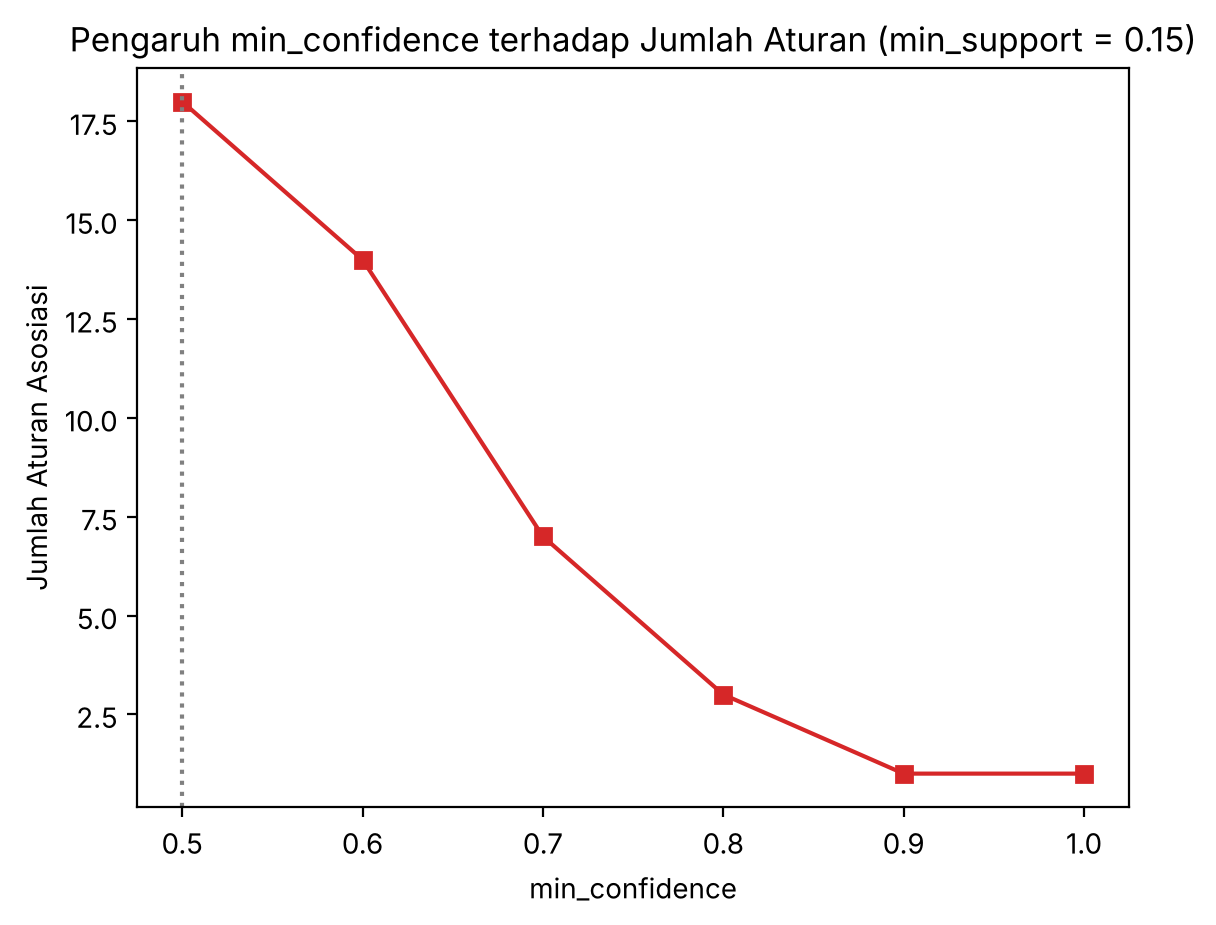

In [15]:
sweep_conf = [0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
n_rules_conf = []
for c in sweep_conf:
    r = association_rules(fi_015, metric='confidence', min_threshold=c)
    n_rules_conf.append(len(r))
    print(f'min_confidence={c:.1f}: {len(r):2d} aturan')

plt.plot(sweep_conf, n_rules_conf, 's-', color='tab:red')
plt.axvline(0.5, color='gray', linestyle=':')
plt.xlabel('min_confidence'); plt.ylabel('Jumlah Aturan Asosiasi')
plt.title('Pengaruh min_confidence terhadap Jumlah Aturan (min_support = 0.15)')
plt.show()

**Penjelasan (Sel 15 – Tugas 1c: sweep min_confidence):** `min_support` dikunci di 0,15 dan `min_confidence` dinaikkan dari 0,5 sampai 1,0. Jumlah aturan turun dari 18 → 14 → 7 → 3 → 1 → 1. Hanya 1 aturan yang tetap bertahan sampai confidence 1,0, yaitu {Mentega, Susu} → {Roti}. Grafik menunjukkan trade-off: ambang makin ketat, aturan makin sedikit tetapi makin andal.

## 16. Tugas 2: leverage & conviction dua aturan

In [16]:
def ambil(rules_df, ant, con):
    return rules_df[(rules_df['antecedents'] == frozenset(ant)) &
                    (rules_df['consequents'] == frozenset(con))].iloc[0]

N = len(df)
hasil = []
for ant, con in [(['Telur'], ['Mie Instan']), (['Roti'], ['Susu'])]:
    r = ambil(rules, ant, con)
    sA  = df[ant].all(axis=1).mean()
    sB  = df[con].all(axis=1).mean()
    sAB = df[ant + con].all(axis=1).mean()
    conf = sAB / sA
    lift = conf / sB
    leverage = sAB - sA * sB
    conviction = (1 - sB) / (1 - conf)
    print(f'Aturan: {ant[0]} -> {con[0]}')
    print(f'  support(A)={sA:.4f}  support(B)={sB:.4f}  support(A,B)={sAB:.4f}')
    print(f'  confidence={conf:.4f}  lift={lift:.4f}')
    print(f'  leverage  ={leverage:.4f}  (mlxtend: {r["leverage"]:.4f})')
    print(f'  conviction={conviction:.4f}  (mlxtend: {r["conviction"]:.4f})\n')

Aturan: Telur -> Mie Instan
  support(A)=0.2500  support(B)=0.3000  support(A,B)=0.1667
  confidence=0.6667  lift=2.2222
  leverage  =0.0917  (mlxtend: 0.0917)
  conviction=2.1000  (mlxtend: 2.1000)

Aturan: Roti -> Susu
  support(A)=0.3000  support(B)=0.3167  support(A,B)=0.2167
  confidence=0.7222  lift=2.2807
  leverage  =0.1217  (mlxtend: 0.1217)
  conviction=2.4600  (mlxtend: 2.4600)



**Penjelasan (Sel 16 – Tugas 2: leverage & conviction):** Dua aturan dihitung manual dari support A, B, dan (A,B), lalu dicocokkan dengan nilai dari mlxtend (hasilnya sama persis, sehingga perhitungan terverifikasi). {Telur} → {Mie Instan}: confidence 0,667, lift 2,222, leverage 0,0917, conviction 2,10. {Roti} → {Susu}: confidence 0,722, lift 2,281, leverage 0,1217, conviction 2,46. Leverage positif berarti kemunculan bersama lebih sering daripada yang diharapkan jika independen; conviction > 1 berarti aturan lebih baik daripada tebakan acak. Roti → Susu sedikit lebih kuat pada ketiga metrik tambahan tersebut.

## 17. Tugas 3: Apriori vs FP-Growth pada min_support = 0.05

In [17]:
t0 = time.perf_counter()
fa = apriori(df, min_support=0.05, use_colnames=True)
t_a = time.perf_counter() - t0

t0 = time.perf_counter()
ff = fpgrowth(df, min_support=0.05, use_colnames=True)
t_f = time.perf_counter() - t0

same = set(frozenset(s) for s in fa['itemsets']) == set(frozenset(s) for s in ff['itemsets'])
print(f'min_support=0.05  Apriori  : {len(fa)} itemset, {t_a*1000:.2f} ms')
print(f'min_support=0.05  FP-Growth: {len(ff)} itemset, {t_f*1000:.2f} ms')
print('Itemset identik?', same)

min_support=0.05  Apriori  : 42 itemset, 3.14 ms
min_support=0.05  FP-Growth: 42 itemset, 1.60 ms
Itemset identik? True


**Penjelasan (Sel 17 – Tugas 3: Apriori vs FP-Growth pada min_support 0,05):** Ambang diturunkan ke 0,05 sehingga itemset melonjak dari 17 menjadi **42**. Kedua algoritma tetap menghasilkan itemset yang identik. Pada satu kali eksekusi, Apriori ≈ 3,14 ms dan FP-Growth ≈ 1,60 ms.

## 18. Rata-rata waktu dari 200 kali eksekusi

In [18]:
def waktu(fn, ms, n=200):
    ts = []
    for _ in range(n):
        t0 = time.perf_counter(); fn(df, min_support=ms, use_colnames=True)
        ts.append(time.perf_counter() - t0)
    return np.mean(ts) * 1000

print('Rata-rata dari 200 kali eksekusi (ms):')
rows = []
for ms in [0.15, 0.05]:
    ta, tf = waktu(apriori, ms), waktu(fpgrowth, ms)
    n_it = len(apriori(df, min_support=ms, use_colnames=True))
    rows.append((ms, n_it, ta, tf))
    print(f'min_support={ms:.2f}: {n_it:3d} itemset | Apriori {ta:6.2f} ms | '
          f'FP-Growth {tf:6.2f} ms | rasio Apriori/FP-Growth = {ta/tf:.2f}x')

Rata-rata dari 200 kali eksekusi (ms):


min_support=0.15:  17 itemset | Apriori   2.28 ms | FP-Growth   1.45 ms | rasio Apriori/FP-Growth = 1.57x


min_support=0.05:  42 itemset | Apriori   2.34 ms | FP-Growth   1.43 ms | rasio Apriori/FP-Growth = 1.63x


**Penjelasan (Sel 18 – Rata-rata 200 kali eksekusi):** Fungsi `waktu()` menjalankan algoritma 200 kali lalu merata-ratakan waktunya agar lebih stabil daripada sekali ukur. Hasil: pada 0,15 Apriori 2,28 ms vs FP-Growth 1,45 ms (rasio 1,57×); pada 0,05 Apriori 2,34 ms vs FP-Growth 1,43 ms (rasio 1,63×). FP-Growth konsisten ±1,6× lebih cepat. Pada dataset sekecil ini selisih absolutnya hanya sekitar 1 ms, keunggulan FP-Growth baru terasa besar pada data yang jauh lebih banyak.

## 19. Grafik perbandingan

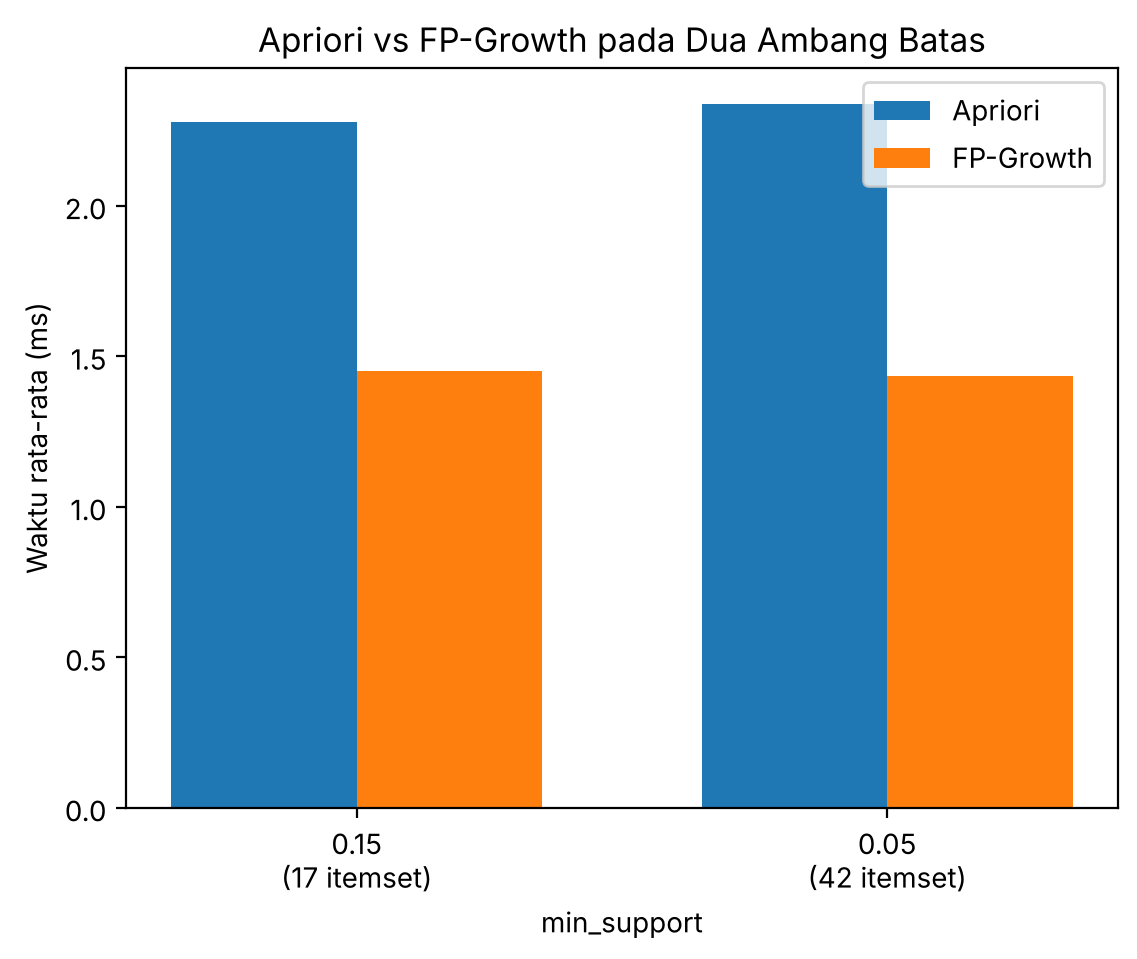

In [19]:
labels = ['0.15\n(%d itemset)' % rows[0][1], '0.05\n(%d itemset)' % rows[1][1]]
x = np.arange(2); w = 0.35
plt.bar(x - w/2, [rows[0][2], rows[1][2]], w, label='Apriori')
plt.bar(x + w/2, [rows[0][3], rows[1][3]], w, label='FP-Growth')
plt.xticks(x, labels)
plt.xlabel('min_support'); plt.ylabel('Waktu rata-rata (ms)')
plt.title('Apriori vs FP-Growth pada Dua Ambang Batas')
plt.legend()
plt.show()

**Penjelasan (Sel 19 – Grafik perbandingan):** Diagram batang berkelompok yang menampilkan waktu rata-rata Apriori dan FP-Growth pada dua ambang batas (0,15 dengan 17 itemset dan 0,05 dengan 42 itemset). Batang FP-Growth lebih rendah di kedua kondisi.

## 20. Tugas 4: dataset toko baju

In [21]:
# Dataset toko baju dibangkitkan dengan random.seed(42), lalu disimpan ke
# transactions_toko_baju.csv (Lampiran B).
random.seed(42)
barang = ['Kemeja', 'Celana Bahan', 'Blazer', 'Kaos', 'Celana Jeans',
          'Jaket', 'Hoodie', 'Celana Jogger', 'Blouse', 'Rok']
transactions_tb = []
for _ in range(50):
    r = random.random()
    if r < 0.26:      # kelompok kantor pria
        t = {'Kemeja', 'Celana Bahan'}
        if random.random() < 0.5: t.add('Blazer')
    elif r < 0.50:    # kelompok kasual
        t = {'Kaos', 'Celana Jeans'}
        if random.random() < 0.35: t.add('Jaket')
    elif r < 0.66:    # kelompok santai
        t = {'Hoodie', 'Celana Jogger'}
    elif r < 0.84:    # kelompok kantor wanita
        t = {'Blouse', 'Rok'}
    else:             # pembelian tunggal
        t = {random.choice(barang)}
    if random.random() < 0.10: t.add('Kaos')
    transactions_tb.append(sorted(t))

pd.DataFrame({'transaction_id': [f'B{i}' for i in range(1, 51)],
              'items': [', '.join(t) for t in transactions_tb]}
             ).to_csv('transactions_toko_baju.csv', index=False)

print(len(transactions_tb), 'transaksi,', len({i for t in transactions_tb for i in t}), 'jenis item')
for i, t in enumerate(transactions_tb[:5], 1):
    print(f'B{i}: {t}')

50 transaksi, 10 jenis item
B1: ['Celana Jogger', 'Hoodie', 'Kaos']
B2: ['Celana Jeans', 'Jaket', 'Kaos']
B3: ['Blouse', 'Rok']
B4: ['Blazer', 'Celana Bahan', 'Kaos', 'Kemeja']
B5: ['Celana Bahan', 'Kaos', 'Kemeja']


**Penjelasan (Sel 20 – Tugas 4: membuat dataset toko baju):** Sel ini membangkitkan 50 transaksi toko baju secara acak dengan `random.seed(42)` agar hasilnya selalu sama saat dijalankan ulang. Ada pola yang sengaja ditanam: kelompok kantor pria (Kemeja + Celana Bahan, kadang Blazer), kasual (Kaos + Celana Jeans, kadang Jaket), santai (Hoodie + Celana Jogger), kantor wanita (Blouse + Rok), dan pembelian tunggal, ditambah peluang 10% Kaos ikut dibeli. Hasilnya disimpan ke `transactions_toko_baju.csv`: 50 transaksi dan 10 jenis item.

## 21. Frekuensi item toko baju

In [22]:
cnt_tb = Counter()
for t in transactions_tb:
    cnt_tb.update(t)
for item, freq in cnt_tb.most_common():
    print(f'{item:15s}: {freq:2d} (support = {freq/len(transactions_tb):.3f})')

Celana Bahan   : 17 (support = 0.340)
Kemeja         : 17 (support = 0.340)
Kaos           : 15 (support = 0.300)
Celana Jeans   : 12 (support = 0.240)
Jaket          :  8 (support = 0.160)
Blouse         :  8 (support = 0.160)
Rok            :  8 (support = 0.160)
Blazer         :  8 (support = 0.160)
Celana Jogger  :  7 (support = 0.140)
Hoodie         :  7 (support = 0.140)


**Penjelasan (Sel 21 – Frekuensi item toko baju):** Celana Bahan dan Kemeja paling sering muncul (masing-masing 17 kali, support 0,340), disusul Kaos (0,300) dan Celana Jeans (0,240). Hoodie dan Celana Jogger paling jarang (7 kali, support 0,140). Semua item punya support ≥ 0,14 sehingga seluruhnya lolos `min_support = 0,10` pada sel berikutnya.

## 22. Pipeline: one-hot -> Apriori -> aturan

In [23]:
te_tb = TransactionEncoder()
df_tb = pd.DataFrame(te_tb.fit(transactions_tb).transform(transactions_tb), columns=te_tb.columns_)
print('Ukuran matriks one-hot:', df_tb.shape)

MIN_SUP_TB, MIN_CONF_TB = 0.10, 0.6
freq_tb = apriori(df_tb, min_support=MIN_SUP_TB, use_colnames=True)
rules_tb = association_rules(freq_tb, metric='confidence', min_threshold=MIN_CONF_TB)
rules_tb = rules_tb.sort_values('lift', ascending=False).reset_index(drop=True)
print(f'min_support={MIN_SUP_TB}, min_confidence={MIN_CONF_TB}')
print('Jumlah frequent itemset:', len(freq_tb))
print('Jumlah aturan asosiasi :', len(rules_tb))
print(rules_tb[cols].round(3).to_string(index=False))

Ukuran matriks one-hot: (50, 10)
min_support=0.1, min_confidence=0.6
Jumlah frequent itemset: 20
Jumlah aturan asosiasi : 21
                      antecedents                       consequents  support  confidence  lift
              frozenset({Hoodie})        frozenset({Celana Jogger})     0.14       1.000 7.143
       frozenset({Celana Jogger})               frozenset({Hoodie})     0.14       1.000 7.143
               frozenset({Jaket})   frozenset({Kaos, Celana Jeans})     0.16       1.000 5.000
  frozenset({Kaos, Celana Jeans})                frozenset({Jaket})     0.16       0.800 5.000
                 frozenset({Rok})               frozenset({Blouse})     0.12       0.750 4.688
              frozenset({Blouse})                  frozenset({Rok})     0.12       0.750 4.688
        frozenset({Celana Jeans})          frozenset({Kaos, Jaket})     0.16       0.667 4.167
               frozenset({Jaket})         frozenset({Celana Jeans})     0.16       1.000 4.167
         frozenset({

**Penjelasan (Sel 22 – Pipeline toko baju):** Alur yang sama seperti toko kelontong diterapkan: one-hot (50 × 10) → Apriori (`min_support` 0,10) → aturan (`min_confidence` 0,6). Hasil: **20 frequent itemset** dan **21 aturan**. Aturan terkuat adalah Hoodie ↔ Celana Jogger (confidence 1,000, lift 7,143), lalu Jaket → {Kaos, Celana Jeans} (lift 5,000) dan Rok ↔ Blouse (confidence 0,75, lift 4,688). Pola ini cocok dengan kelompok pembelian yang ditanam di Sel 20. Contoh aplikasi bisnisnya: tawarkan paket Hoodie + Celana Jogger atau Kemeja + Celana Bahan.

## 23. Visualisasi toko baju

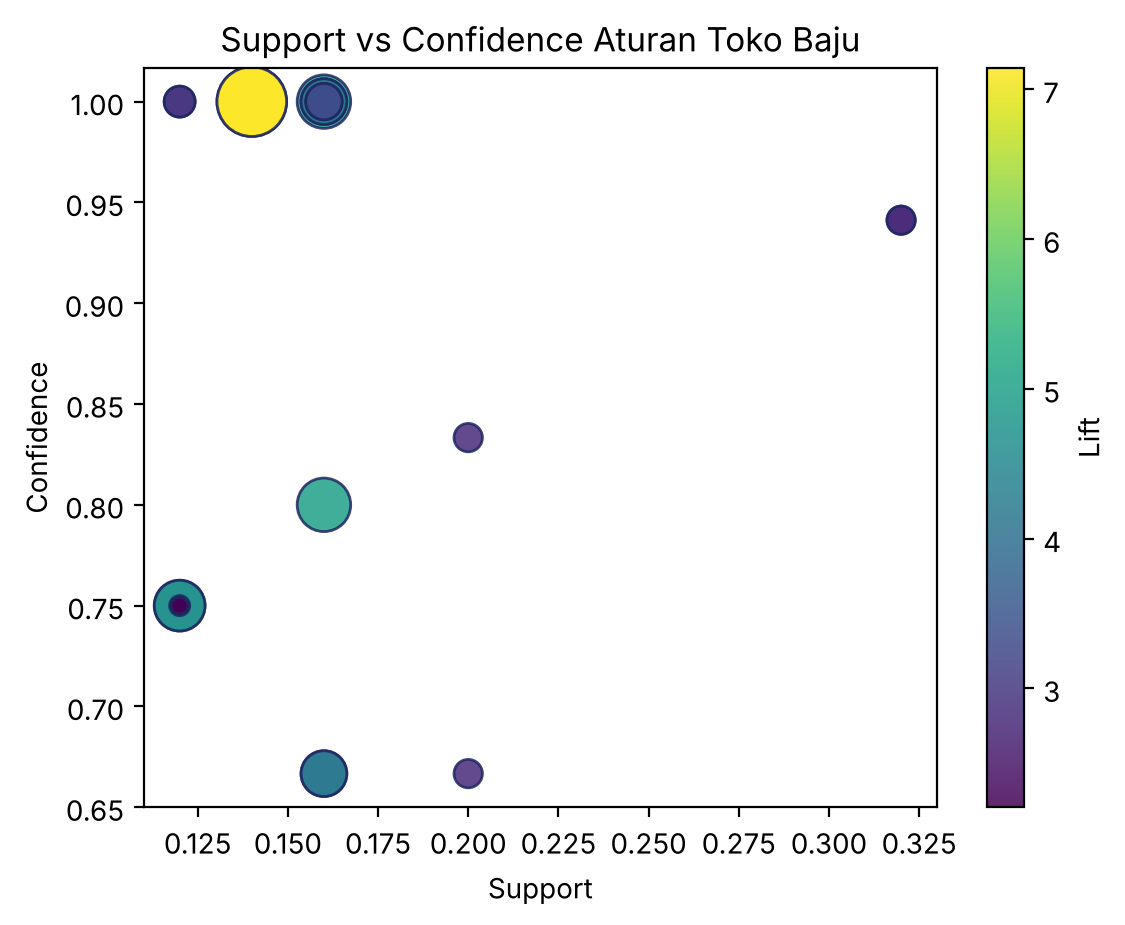

In [24]:
sizes = (rules_tb['lift'] - rules_tb['lift'].min() + 0.3) * 120
sc = plt.scatter(rules_tb['support'], rules_tb['confidence'], s=sizes,
                 c=rules_tb['lift'], cmap='viridis', alpha=0.85, edgecolor='#1E2761')
plt.colorbar(sc, label='Lift')
plt.xlabel('Support'); plt.ylabel('Confidence')
plt.title('Support vs Confidence Aturan Toko Baju')
plt.show()

**Penjelasan (Sel 23a – Scatter toko baju):** Scatter plot support vs confidence untuk 21 aturan toko baju, dengan ukuran dan warna titik menunjukkan lift. Banyak aturan berada di confidence tinggi (0,75–1,0), tetapi support-nya relatif kecil (0,12–0,32), wajar karena tiap kelompok pembeli hanya sebagian dari seluruh transaksi.

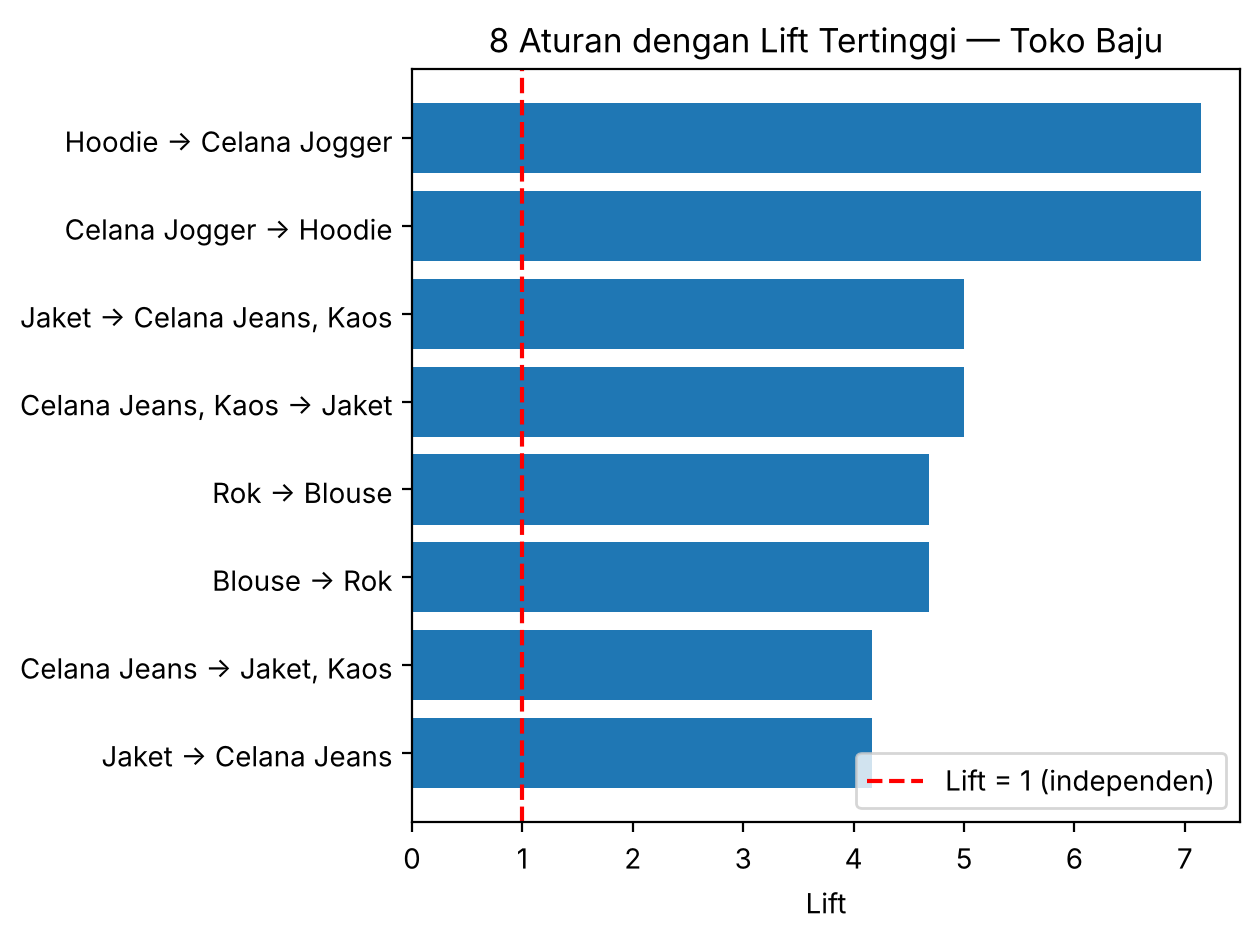

In [25]:
top = rules_tb.head(8)
labels = [', '.join(sorted(a)) + ' → ' + ', '.join(sorted(c))
          for a, c in zip(top['antecedents'], top['consequents'])]
plt.barh(labels[::-1], top['lift'][::-1])
plt.axvline(1, color='red', linestyle='--', label='Lift = 1 (independen)')
plt.xlabel('Lift')
plt.title('8 Aturan dengan Lift Tertinggi — Toko Baju')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

**Penjelasan (Sel 23b – 8 aturan lift tertinggi toko baju):** Diagram batang horizontal 8 aturan dengan lift terbesar (garis merah = lift 1). Seluruhnya berlift jauh di atas 1, terutama pasangan Hoodie–Celana Jogger, yang menunjukkan asosiasi pembelian sangat kuat pada data ini. Karena data dibangkitkan dengan pola buatan, lift setinggi ini wajar dan belum tentu mencerminkan toko sungguhan.

## Kesimpulan

1. **Pipeline:** data transaksi → one-hot encoding → frequent itemset (Apriori/FP-Growth) → aturan asosiasi (support, confidence, lift) → visualisasi dan interpretasi.
2. **Pengaruh ambang batas:** `min_support` dan `min_confidence` yang makin tinggi menghasilkan itemset/aturan yang makin sedikit tetapi lebih andal; ambang yang terlalu tinggi membuang pola penting (pada `min_support` ≥ 0,25 tidak ada aturan sama sekali).
3. **Toko kelontong:** kombinasi Susu–Mentega–Roti, Sabun–Shampo, Telur–Mie Instan, dan Kecap–Mie Instan paling kuat. {Mentega, Susu} → {Roti} mencapai confidence 1,0 dan lift 3,33.
4. **Metrik tambahan:** leverage positif dan conviction > 1 pada Telur → Mie Instan dan Roti → Susu mengonfirmasi bahwa asosiasinya nyata, bukan kebetulan.
5. **Apriori vs FP-Growth:** hasil itemset identik di semua percobaan; FP-Growth konsisten ±1,6× lebih cepat (rata-rata 200 kali eksekusi), meski selisih absolutnya kecil pada data sekecil ini.
6. **Toko baju:** aturan terkuat Hoodie ↔ Celana Jogger (lift 7,14) sesuai pola yang sengaja dibangkitkan, dan dapat dipakai untuk ide paket bundling atau penataan produk.